# 03 — Feature engineering and validation

**Question:** Which measurements of level, movement, variability and recent change can we calculate reliably, and what do they preserve or conceal?

A *feature* is a numerical description of readings already available. Here we calculate 19 candidates in physical units. We validate their arithmetic, timing and empirical behaviour; we do **not** fit a detector, choose alarm thresholds or claim detection improvement.

Use the separate normal recording and 26 development experiments only. The eight reserved experiments remain unopened. Each file is a separate recording from the same physical testbed; recording names and intervention families are grouping metadata, not predictors. Annotations are kept separate. No annotation determines a window, reference or feature.

**Notebook sequence:** 01 assesses data; 02 calculates reference values; 03 creates and validates features; 04 will evaluate detectors. This replaces the earlier detection-stage numbering in Notebook 02.

In [1]:
from pathlib import Path
import json
import hashlib
import sys
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ts_anomaly.skab import METRICS, load_development
from ts_anomaly.features import engineer_recording, trailing_statistics, feature_summary

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'configs/skab.json').exists(), 'Open the repository or its notebooks folder.'
settings = json.loads((ROOT / 'configs/skab.json').read_text())
options, specification = settings['baselines'], settings['features']
OUT = ROOT / 'outputs/skab_features'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 3), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_columns', 12)

recordings, annotations = load_development(ROOT / 'data/skab', settings)
manifest = pd.DataFrame(settings['files'])
development = manifest.loc[manifest.partition.eq('development'), 'recording_id'].tolist()
reserved = set(manifest.loc[manifest.partition.eq('reserved_test'), 'recording_id'])
assert len(recordings) == 27 and len(development) == 26
assert reserved.isdisjoint(recordings)
measurements = list(METRICS)
step = pd.Timedelta(options['aggregation_interval'])
print(f'{len(recordings)} permitted recordings; {len(reserved)} reserved files never requested.')
print('Source commit:', settings['source_commit'])
print('Python:', sys.version.split()[0], '| Timezone: unknown; no UTC conversion.')

27 permitted recordings; 8 reserved files never requested.
Source commit: b2c0d46c2971dcbfe71e26087b6d231998bb91c2
Python: 3.13.2 | Timezone: unknown; no UTC conversion.


## 1. What Notebook 02 established

| Executed finding | Consequence here |
|---|---|
| Initial levels differ greatly between recordings. | Subtract each recording's permitted initial median. This is local calibration, not direct transfer of one universal level. |
| Thermal persistence reduces prediction error but can follow sustained departures. | Preserve both initial-level departure and recent-history error. |
| Pressure/flow can have tied readings and zero calibration MAD. | Retain physical units and valid zeros; no division by MAD or arbitrary small constants. |
| Current has candidate 80–95-second cycles in valve recordings. | A rising slope can be an ordinary cycle phase. Assess window sensitivity, not a seasonal detector. |
| Vibration associations and extrapolation vary across examples. | Omit the optional conditional residual. Retain both vibration levels and IQRs. |
| The normal file shares 572 timestamped sensor rows with `other/5`. | Do not treat these as independent assets or independent train/test groups in Notebook 04. |

The normal file is calculated separately as a diagnostic. It is not pooled into development summaries or used as the level reference in this notebook. Notebook 02's calculations remain unchanged.

In [2]:
protocol = pd.DataFrame([
    ['Feature endpoint', 'Completed five-second endpoint; input interval excludes that endpoint'],
    ['Local median', 'First 60 elapsed seconds; 180 seconds for sensitivity'],
    ['Calibration support', 'At least 80% occupied native seconds and an eligible whole five-second mean'],
    ['Five-second mean', 'At least four finite readings; window-edge and internal gap checks'],
    ['Slope / IQR', 'Previous 30 seconds of native readings; at least 80% occupied seconds'],
    ['Continuity', 'No gap >2 s; check left edge and age at right edge without future readings'],
    ['History error', 'Two consecutive eligible means; raw continuity and missing-reading checks'],
    ['Comparison period', 'Whole target bins starting at or after elapsed 180 s'],
], columns=['choice', 'definition'])
display(protocol)
print('These are declared experimental settings, not statistically optimal universal parameters.')

,choice,definition
0,Feature endpoint,Completed five-second endpoint; input interval...
1,Local median,First 60 elapsed seconds; 180 seconds for sens...
2,Calibration support,At least 80% occupied native seconds and an el...
3,Five-second mean,At least four finite readings; window-edge and...
4,Slope / IQR,Previous 30 seconds of native readings; at lea...
5,Continuity,No gap >2 s; check left edge and age at right ...
6,History error,Two consecutive eligible means; raw continuity...
7,Comparison period,Whole target bins starting at or after elapsed...


These are declared experimental settings, not statistically optimal universal parameters.


## 2. Definitions: what each number means

For completed endpoint $t$, let $\bar x_5(t)$ be the mean of finite readings in $[t-5s,t)$. Let $m_C$ be the median of eligible whole five-second means within $[t_0,t_0+C)$, where $C$ is 60 or 180 seconds.

- **Level departure:** $\bar x_5(t)-m_C$. Keeps a lasting shift visible. Calibration can absorb an already abnormal starting condition.
- **Slope:** fit a straight line to native readings in $[t-30s,t)$ using actual time in minutes. The slope is $\sum(u_i-\bar u)(x_i-\bar x)/\sum(u_i-\bar u)^2$. It describes direction and speed, including ordinary oscillation or a step; it is not a significance test.
- **Variability:** native-window $Q_{.75}-Q_{.25}$. Keeps local spread, but cannot distinguish noise from trend or mixed regimes. It can miss isolated extremes.
- **History error:** $\bar x_5(t)-\bar x_5(t-5s)$, only when both windows and their connection are supported. It describes recent change and can become small after a sustained shift.

Windows overlap, so neighbouring features are dependent. A five-second mean smooths brief events and the recorded vibration channels already contain RMS summaries; raw vibration spectra cannot be reconstructed.

In [3]:
definitions = []
for name, metric in METRICS.items():
    for kind, selected, window, calculation, limitation in [
        ('level', measurements, '5 s', 'Five-second mean minus initial median of means', 'Starting condition may be abnormal'),
        ('slope', specification['slope_measurements'], '30 s', 'OLS slope of native readings against elapsed minutes', 'Cycling or a step can produce a large slope'),
        ('iqr', specification['variability_measurements'], '30 s', 'Native Q75 minus Q25', 'Trend contributes; isolated extremes can be missed'),
        ('history', specification['history_measurements'], 'two 5 s bins', 'Current mean minus previous eligible mean', 'Can conceal a lasting level change'),
    ]:
        if name in selected:
            definitions.append({'feature': f'{name}__{kind}', 'measurement': name,
                'kind': kind, 'unit': (f'({metric.unit})/min' if '/' in metric.unit else f'{metric.unit}/min') if kind == 'slope' else metric.unit,
                'window': window, 'calibration': '60 s (180 s sensitivity)' if kind == 'level' else 'none',
                'representation': 'native readings' if kind in ['slope', 'iqr'] else 'completed five-second means',
                'availability_rule': ('supported calibration + supported target bin' if kind == 'level' else
                                     'two supported connected bins' if kind == 'history' else
                                     '80% occupied seconds + gap/edge checks'),
                'calculation': calculation, 'limitation': limitation})
dictionary = pd.DataFrame(definitions).set_index('feature')
set_a = dictionary.index[dictionary.kind.eq('level')].tolist()
set_b = dictionary.index.tolist()
assert len(set_a) == 8 and len(set_b) == 19
display(dictionary[['unit', 'window', 'calibration', 'calculation']])
dictionary.to_csv(OUT / 'feature_dictionary.csv')

,unit,window,calibration,calculation
feature,,,,
Accelerometer1RMS__level,g,5 s,60 s (180 s sensitivity),Five-second mean minus initial median of means
Accelerometer1RMS__iqr,g,30 s,none,Native Q75 minus Q25
Accelerometer2RMS__level,g,5 s,60 s (180 s sensitivity),Five-second mean minus initial median of means
Accelerometer2RMS__iqr,g,30 s,none,Native Q75 minus Q25
Current__level,A,5 s,60 s (180 s sensitivity),Five-second mean minus initial median of means
Current__slope,A/min,30 s,none,OLS slope of native readings against elapsed m...
Current__iqr,A,30 s,none,Native Q75 minus Q25
Pressure__level,bar,5 s,60 s (180 s sensitivity),Five-second mean minus initial median of means
Temperature__level,degC,5 s,60 s (180 s sensitivity),Five-second mean minus initial median of means


## 3. Calculate features and retain their support

References use **five-second means**, matching the measured quantity being compared. The fitting interval is half-open; a mean straddling its end cannot enter calibration. Level features begin with the first wholly post-calibration bin. Slopes, IQRs and history errors need no fitted centre and can become available earlier.

The existing completed-window and persistence functions are reused. Notebook 03 additionally masks individual means whose window edges are stale or interrupted; this does not alter Notebook 02. At a right edge we inspect age of the latest available reading, never the next reading. Calibration support is the declared occupancy rule plus at least one eligible mean; the number of means is reported, not treated as an effective independent sample size.

In [4]:
values, supports, references = {}, {}, {}
for seconds in options['calibration_seconds']:
    values[seconds], supports[seconds], references[seconds] = {}, {}, {}
    for identifier, data in recordings.items():
        result, support, reference = engineer_recording(
            data, measurements, specification['slope_measurements'],
            specification['variability_measurements'], specification['history_measurements'],
            calibration_seconds=seconds, frequency=options['aggregation_interval'],
            min_count=options['minimum_bin_observations'], window=specification['window'],
            minimum_occupancy=options['minimum_occupancy'], max_gap=settings['gap_threshold'],
            nominal_interval=settings['nominal_interval'])
        values[seconds][identifier] = result[set_b]
        supports[seconds][identifier] = support
        references[seconds][identifier] = reference
        available = support.pivot(index='timestamp', columns='feature', values='available')
        assert np.array_equal(available[set_b].to_numpy(), result[set_b].notna().to_numpy())
print('Calculated both fixed calibration protocols for all 27 permitted recordings.')
calibration = pd.concat([frame.assign(recording_id=identifier)
    for seconds in references for identifier, frame in references[seconds].items()], ignore_index=True)
calibration.to_csv(OUT / 'calibration.csv', index=False)
calibration_status = calibration.loc[calibration.recording_id.isin(development)].groupby(
    ['calibration_seconds', 'recording_id']).agg(
    occupancy=('occupancy', 'min'), eligible_means=('observations', 'min'),
    all_signals_supported=('supported', 'all'))
display(calibration_status.groupby(level=0).agg(
    supported_recordings=('all_signals_supported', 'sum'),
    minimum_means=('eligible_means', 'min'), maximum_means=('eligible_means', 'max')))
display(calibration_status.loc[~calibration_status.all_signals_supported])

Calculated both fixed calibration protocols for all 27 permitted recordings.


,supported_recordings,minimum_means,maximum_means
calibration_seconds,,,
60,25,5,12
180,24,11,36


occupancy  eligible_means  \
calibration_seconds recording_id                              
60                  other/13       0.683333               5   
180                 other/13       0.661111              11   
                    other/2        0.577778              21   

                                  all_signals_supported  
calibration_seconds recording_id                         
60                  other/13                      False  
180                 other/13                      False  
                    other/2                       False

In [5]:
# The same post-180-second population is requested for both calibration protocols.
post_calibration = {}
for identifier in recordings:
    frame = values[60][identifier]
    cutoff = recordings[identifier].timestamp.iloc[0] + pd.Timedelta(seconds=180)
    post_calibration[identifier] = frame.index - step >= cutoff

summaries = []
for seconds in values:
    for identifier in development:
        frame = values[seconds][identifier].loc[post_calibration[identifier]]
        summaries.append(feature_summary(frame).assign(recording_id=identifier,
                                                       calibration_seconds=seconds))
summary = pd.concat(summaries, ignore_index=True)
summary.to_csv(OUT / 'per_recording_feature_summary.csv', index=False)
primary = summary.loc[summary.calibration_seconds.eq(60)]
quality = primary.groupby('feature').agg(
    supported_recordings=('available', lambda x: int(x.gt(0).sum())),
    minimum_availability=('availability', 'min'), median_availability=('availability', 'median'),
    fewest_distinct=('distinct', 'min'), zero_values=('zeros', 'sum'),
    median_within_recording_iqr=('iqr', 'median'),
    longest_constant_span_s=('longest_constant_span_s', 'max'))
display(quality.reindex(set_b).round(4))
print('Availability uses every requested post-calibration endpoint, including gaps; it is not equipment uptime.')

,supported_recordings,minimum_availability,median_availability,fewest_distinct,zero_values,median_within_recording_iqr,longest_constant_span_s
feature,,,,,,,
Accelerometer1RMS__level,25,0.0000,1.0,0,0,0.0003,0.0
Accelerometer1RMS__iqr,26,0.7211,1.0,115,0,0.0002,10.0
Accelerometer2RMS__level,25,0.0000,1.0,0,0,0.0015,0.0
Accelerometer2RMS__iqr,26,0.7211,1.0,117,0,0.0005,10.0
Current__level,25,0.0000,1.0,0,0,0.3239,0.0
Current__slope,26,0.7211,1.0,119,0,1.1156,0.0
Current__iqr,26,0.7211,1.0,119,0,0.1535,10.0
Pressure__level,25,0.0000,1.0,0,547,0.1476,20.0
Temperature__level,25,0.0000,1.0,0,0,0.8827,0.0


Availability uses every requested post-calibration endpoint, including gaps; it is not equipment uptime.


**Observed support:** the primary 60-second protocol yields 11–12 eligible calibration means per supported signal, in 25/26 recordings. `other/13` has only 68.3% occupied calibration seconds and remains unavailable for all eight level departures. The 180-second alternative also loses `other/2` (57.8% occupancy), supporting 24/26. Longer calibration is therefore not a universal remedy. These few dependent means do not establish a stable or healthy starting condition.

Support tables keep one primary reason for each unavailable feature, with occupancy, first/last-reading age and maximum observed gap for audit. When several problems coexist, the first reason takes precedence; `source_reason` retains the underlying window status. For history features, counts describe the target bin; separate previous-bin and raw-connection fields describe its additional dependency. Valid zeros are never replaced with missing values.

In [6]:
reason_frames = []
for identifier in development:
    support = supports[60][identifier]
    requested = values[60][identifier].index[post_calibration[identifier]]
    selected = support.loc[support.timestamp.isin(requested)]
    reason_frames.append(selected.groupby(['feature', 'reason']).size().rename('endpoints')
                         .reset_index().assign(recording_id=identifier))
reasons = pd.concat(reason_frames, ignore_index=True)
reasons.to_csv(OUT / 'availability_reasons.csv', index=False)
display(reasons.groupby('reason').endpoints.sum().sort_values(ascending=False).to_frame())

# Retain each recording rather than silently keeping only complete 19-feature rows.
recording_availability = []
for identifier in development:
    frame = values[60][identifier].loc[post_calibration[identifier]]
    a, b = frame[set_a].notna().all(axis=1), frame[set_b].notna().all(axis=1)
    recording_availability.append({'recording_id': identifier, 'requested': len(frame),
        'level_only_complete': int(a.sum()), 'expanded_complete': int(b.sum()),
        'common_complete': int((a & b).sum())})
recording_availability = pd.DataFrame(recording_availability)
display(recording_availability)
recording_availability.to_csv(OUT / 'candidate_set_availability.csv', index=False)

,endpoints
reason,
available,94184
unsupported_calibration,1520
no_observations,1253
low_occupancy,744
collection_gap,105
history_unavailable,26
stale_tail,18


,recording_id,requested,level_only_complete,expanded_complete,common_complete
0,other/1,119,119,119,119
1,other/10,243,243,243,243
2,other/11,214,213,212,212
3,other/13,190,0,0,0
4,other/14,154,154,154,154
5,other/2,176,142,137,137
6,other/3,203,203,203,203
7,other/5,205,205,205,205
8,other/6,204,204,204,204
9,other/7,191,191,191,191


## 4. What the features show on real recordings

These examples are fixed in advance: `valve1/1`, `other/10` and gap-affected `other/2`. They illustrate behaviour; the preceding tables cover all 26 development recordings. Horizontal zero lines are reference values, not alarm thresholds. Shading shows only elapsed-time calibration. No feature is selected by how strongly it follows an annotation.

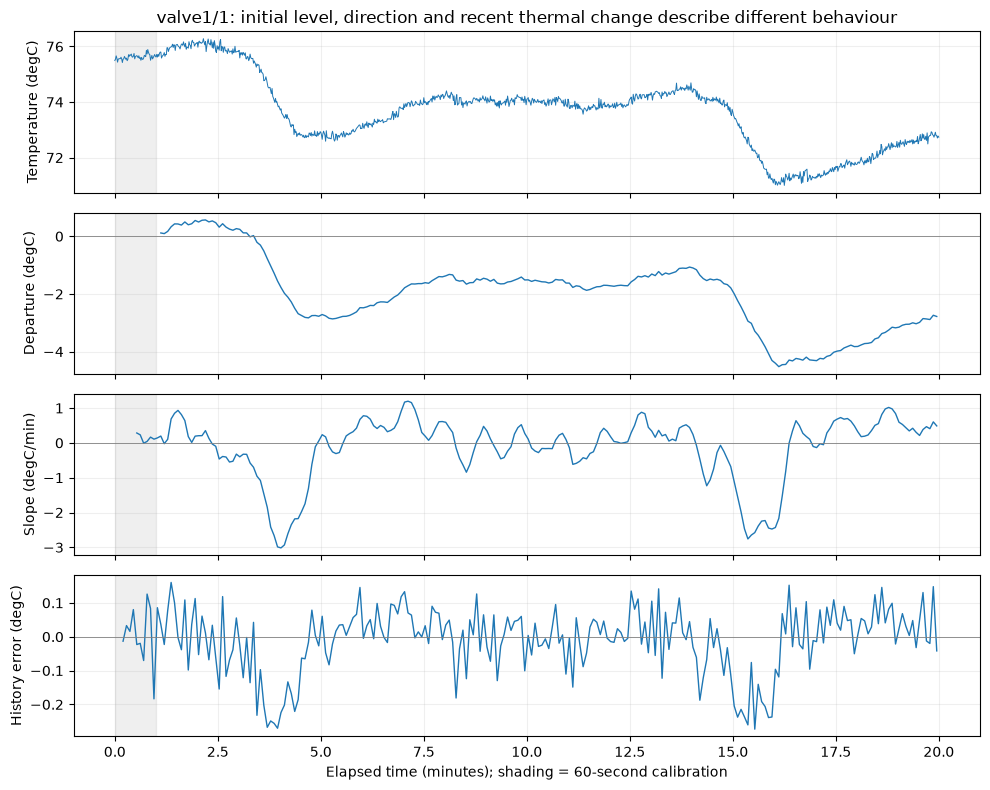

,feature,median,p05,p95,availability
236,Temperature__level,-1.7746,-4.2841,-1.0989,1.0
237,Temperature__slope,0.1087,-2.4437,0.8353,1.0
238,Temperature__history,0.0037,-0.2313,0.1177,1.0


In [7]:
def elapsed(index, identifier):
    return (index - recordings[identifier].timestamp.iloc[0]).total_seconds() / 60


def native_line(ax, identifier, name):
    data = recordings[identifier]
    # Separate line segments rather than drawing a trajectory through a collection gap.
    segments = data.timestamp.diff().gt(pd.Timedelta(settings['gap_threshold'])).cumsum()
    for _, group in data.groupby(segments):
        ax.plot(elapsed(pd.DatetimeIndex(group.timestamp), identifier), group[name],
                color='tab:blue', linewidth=.7)
    ax.set_ylabel(f'{name} ({METRICS[name].unit})')


def finish(fig, filename):
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=130, bbox_inches='tight')
    plt.show()

identifier = 'valve1/1'
frame = values[60][identifier]
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
native_line(axes[0], identifier, 'Temperature')
for ax, kind, label in zip(axes[1:], ['level', 'slope', 'history'],
                         ['Departure (degC)', 'Slope (degC/min)', 'History error (degC)']):
    ax.plot(elapsed(frame.index, identifier), frame[f'Temperature__{kind}'], linewidth=1)
    ax.axhline(0, color='grey', linewidth=.6)
    ax.set_ylabel(label)
for ax in axes:
    ax.axvspan(0, 1, color='grey', alpha=.12)
axes[0].set_title('valve1/1: initial level, direction and recent thermal change describe different behaviour')
axes[-1].set_xlabel('Elapsed time (minutes); shading = 60-second calibration')
finish(fig, 'temperature-features.png')
thermal = primary.loc[primary.recording_id.eq(identifier) & primary.feature.str.startswith('Temperature__')]
display(thermal[['feature', 'median', 'p05', 'p95', 'availability']].round(4))

**Observed:** in `valve1/1`, post-180-second temperature departures have median **−1.775 °C**, while five-second history errors have median **+0.0037 °C**. Around minutes 9–13 the temperature stays below its starting level while recent changes remain small. The sharp cooling episodes near minutes 4 and 16 also create negative slopes and history errors.

The three features answer different questions: distance from the initial level, direction over 30 seconds, and change between neighbouring means. A small history error does not mean recovery to the initial condition. Neither cooling nor warming alone establishes a fault.

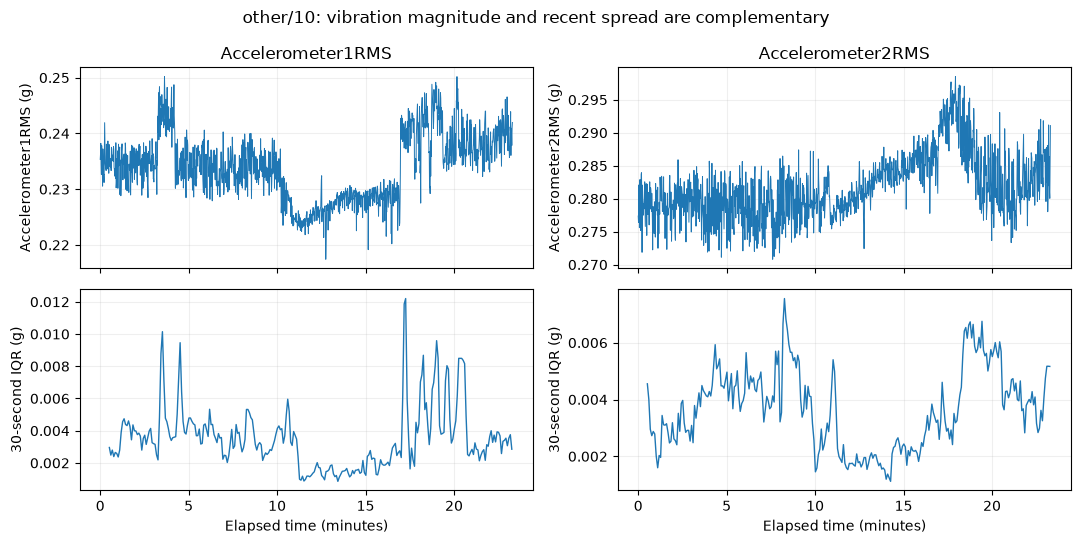

,feature,median,p05,p95,zeros
19,Accelerometer1RMS__level,-0.00097,-0.01023,0.00906,0
20,Accelerometer1RMS__iqr,0.00321,0.00118,0.00815,0
21,Accelerometer2RMS__level,0.00156,-0.00267,0.01188,0
22,Accelerometer2RMS__iqr,0.00381,0.00163,0.00614,0


In [8]:
identifier = 'other/10'
frame = values[60][identifier]
fig, axes = plt.subplots(2, 2, figsize=(11, 5.5), sharex=True)
for column, name in enumerate(['Accelerometer1RMS', 'Accelerometer2RMS']):
    native_line(axes[0, column], identifier, name)
    axes[0, column].set_title(name)
    axes[1, column].plot(elapsed(frame.index, identifier), frame[f'{name}__iqr'], linewidth=1)
    axes[1, column].set(ylabel='30-second IQR (g)', xlabel='Elapsed time (minutes)')
fig.suptitle('other/10: vibration magnitude and recent spread are complementary')
finish(fig, 'vibration-variability.png')
display(primary.loc[primary.recording_id.eq(identifier) & primary.feature.str.startswith('Accelerometer'),
                    ['feature', 'median', 'p05', 'p95', 'zeros']].round(5))

**Observed:** in `other/10`, both IQRs fall after approximately minute 10 and rise again later, while the two sensor levels follow different trajectories. Post-calibration IQR medians are **0.00321 g** and **0.00381 g**, respectively. The first sensor's lower level after minute 10 coexists with lower spread; level and variability are not the same quantity.

These channels are RMS amplitude summaries. Rolling IQR measures variation **between those summaries**, not vibration energy or a frequency spectrum. Trend inside a window can also raise IQR; this analysis cannot attribute the changes to a specific physical cause.

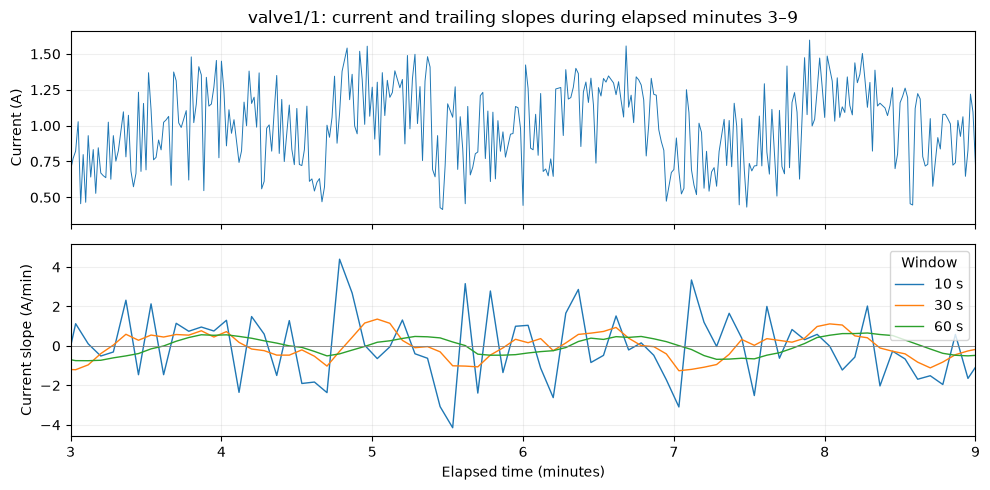

In [9]:
identifier = 'valve1/1'
data, frame = recordings[identifier], values[60][identifier]
current_windows = {}
for seconds in specification['window_sensitivity_seconds']:
    current_windows[seconds] = trailing_statistics(data.set_index('timestamp').Current,
        frame.index, f'{seconds}s', options['minimum_occupancy'], settings['gap_threshold'])
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
native_line(axes[0], identifier, 'Current')
for seconds, report in current_windows.items():
    axes[1].plot(elapsed(report.index, identifier), report.slope, label=f'{seconds} s', linewidth=1)
axes[0].set_title('valve1/1: current and trailing slopes during elapsed minutes 3–9')
axes[1].set(xlim=(3, 9), ylabel='Current slope (A/min)', xlabel='Elapsed time (minutes)')
axes[1].axhline(0, color='grey', linewidth=.6)
axes[1].legend(title='Window')
finish(fig, 'current-window-sensitivity.png')

The current plot is deliberately an elapsed-time slice, not a label-chosen event. Notebook 02 found ordinary cycling on this time scale. Slopes change sign as a cycle rises and falls; shortening the window increases responsiveness and changes what is measured. Slope magnitude alone does not establish deterioration. We retain the predeclared 30-second choice and report alternatives rather than selecting the strongest event response.

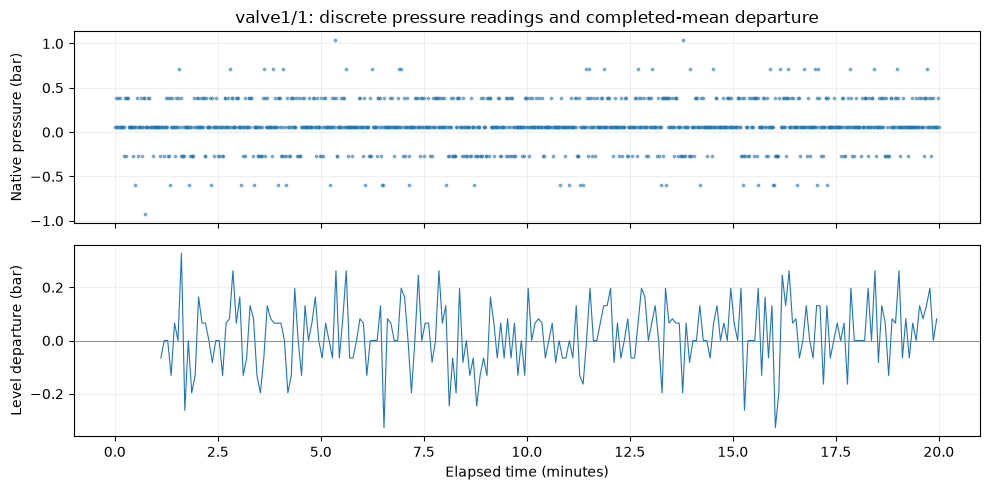

Native distinct pressure readings: 7
Distinct available mean departures: 30
Zero departures: 44 | Unavailable: 12


In [10]:
identifier = 'valve1/1'
data, frame = recordings[identifier], values[60][identifier]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].scatter(elapsed(pd.DatetimeIndex(data.timestamp), identifier), data.Pressure, s=3, alpha=.5)
axes[0].set(title='valve1/1: discrete pressure readings and completed-mean departure', ylabel='Native pressure (bar)')
axes[1].plot(elapsed(frame.index, identifier), frame.Pressure__level, linewidth=.8)
axes[1].axhline(0, color='grey', linewidth=.6)
axes[1].set(ylabel='Level departure (bar)', xlabel='Elapsed time (minutes)')
finish(fig, 'pressure-representation.png')
print('Native distinct pressure readings:', data.Pressure.nunique())
print('Distinct available mean departures:', frame.Pressure__level.nunique())
print('Zero departures:', int(frame.Pressure__level.eq(0).sum()), '| Unavailable:', int(frame.Pressure__level.isna().sum()))

**Observed:** `valve1/1` has **seven** native pressure levels but **30** distinct available mean departures. Of its feature endpoints, **44** departures are exactly zero and **12** are unavailable during calibration. Averaging creates intermediate values; it does not improve sensor resolution or establish a Gaussian distribution.

A zero departure is equality with the calibrated centre. An unavailable departure means there was insufficient permitted information. The native trace remains necessary for brief extremes that averaging can conceal. Negative readings are retained because calibrated validity limits are not established by the source.

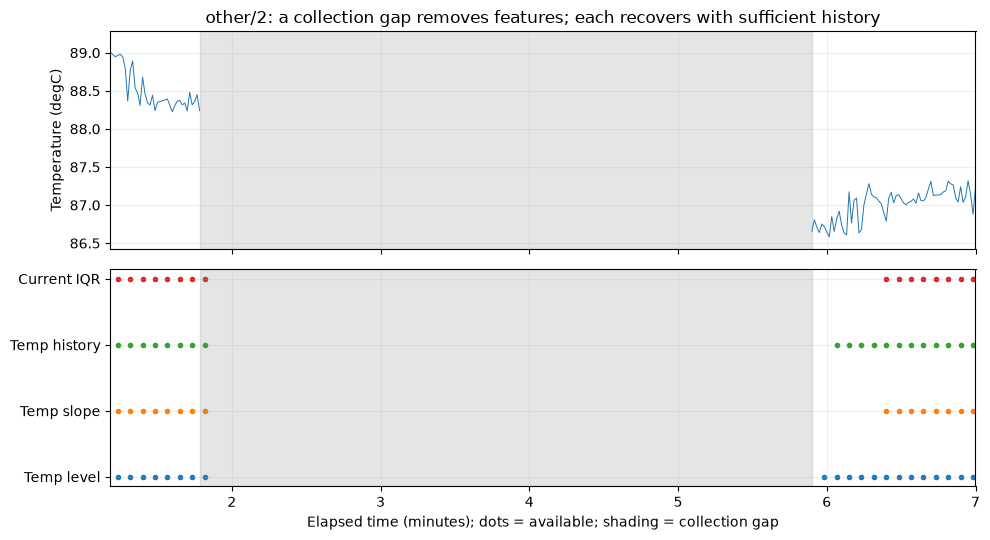

,feature,first_available_after_gap,seconds_after_first_returning_reading
0,Temperature__level,2020-03-01 16:34:15,5.0
1,Temperature__slope,2020-03-01 16:34:40,30.0
2,Temperature__history,2020-03-01 16:34:20,10.0
3,Current__iqr,2020-03-01 16:34:40,30.0


Gap between observed timestamps: 247.0 seconds.


In [11]:
identifier = 'other/2'
data, frame = recordings[identifier], values[60][identifier]
gap_end_position = data.timestamp.diff().idxmax()
gap_start = data.timestamp.loc[gap_end_position - 1]
gap_end = data.timestamp.loc[gap_end_position]
selected_features = ['Temperature__level', 'Temperature__slope', 'Temperature__history', 'Current__iqr']
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
native_line(axes[0], identifier, 'Temperature')
for row, name in enumerate(selected_features):
    present = frame[name].notna()
    axes[1].scatter(elapsed(frame.index[present], identifier), np.full(present.sum(), row), s=9)
axes[1].set_yticks(range(len(selected_features)), ['Temp level', 'Temp slope', 'Temp history', 'Current IQR'])
for ax in axes:
    ax.axvspan(elapsed(pd.DatetimeIndex([gap_start]), identifier)[0],
               elapsed(pd.DatetimeIndex([gap_end]), identifier)[0], color='grey', alpha=.2)
axes[0].set_title('other/2: a collection gap removes features; each recovers with sufficient history')
axes[1].set(xlabel='Elapsed time (minutes); dots = available; shading = collection gap',
            xlim=(elapsed(pd.DatetimeIndex([gap_start]), identifier)[0] - .6,
                  elapsed(pd.DatetimeIndex([gap_end]), identifier)[0] + 1.1))
finish(fig, 'gap-recovery.png')
recovery = []
for name in selected_features:
    after = frame.loc[frame.index > gap_end, name].dropna()
    first = after.index.min()
    recovery.append({'feature': name, 'first_available_after_gap': first,
                     'seconds_after_first_returning_reading': (first - gap_end).total_seconds()})
display(pd.DataFrame(recovery))
print('Gap between observed timestamps:', (gap_end - gap_start).total_seconds(), 'seconds.')

**Observed:** the `other/2` gap spans **247 seconds** between recorded timestamps. After observations resume, temperature level departure first returns after **5 seconds**, history error after **10 seconds**, and 30-second slope/IQR after **30 seconds**. The plot includes one endpoint just after the last pre-gap reading: that feature was available at the time, before later missingness was known.

Recovery follows each feature's information requirement. No line is interpolated through the gap and no absent feature is treated as normal or zero. These recovery times describe this recording's grid alignment; they are not fixed guarantees for every gap.

## 5. Calibration sensitivity: a different starting centre

Compare 60- and 180-second medians calculated from matching five-second means. Use the same wholly post-180-second target bins and the intersection of available level features. A longer calibration changes the centre, not the later target mean: wherever both are available, `departure_180 − departure_60 = centre_60 − centre_180`. Slopes, IQRs and history errors do not depend on this calibration choice.

Report failures and early availability separately. Longer fitting does not automatically create a better reference and can include more ordinary thermal drift or an early disturbance.

In [12]:
calibration_comparisons, early_availability = [], []
for identifier in development:
    a, b = values[60][identifier], values[180][identifier]
    for name in set_a:
        paired = pd.concat([a.loc[post_calibration[identifier], name],
                            b.loc[post_calibration[identifier], name]], axis=1, keys=['60s', '180s']).dropna()
        delta = paired['180s'] - paired['60s']
        calibration_comparisons.append({'recording_id': identifier, 'feature': name,
            'common_endpoints': len(paired), 'departure_180_minus_60': delta.median()})
        early = (a.index - step >= recordings[identifier].timestamp.iloc[0] + pd.Timedelta(seconds=60)) & ~post_calibration[identifier]
        early_availability.append({'recording_id': identifier, 'feature': name,
                                   'early_available_endpoints': int(a.loc[early, name].notna().sum())})
        if len(paired):
            centre60 = references[60][identifier].set_index('measurement').loc[dictionary.loc[name, 'measurement'], 'expected']
            centre180 = references[180][identifier].set_index('measurement').loc[dictionary.loc[name, 'measurement'], 'expected']
            assert np.allclose(delta, centre60 - centre180)
    temporal = dictionary.index[~dictionary.kind.eq('level')]
    pd.testing.assert_frame_equal(a[temporal], b[temporal])
calibration_comparisons = pd.DataFrame(calibration_comparisons)
early_availability = pd.DataFrame(early_availability)
calibration_comparisons.to_csv(OUT / 'calibration_sensitivity.csv', index=False)
early_availability.to_csv(OUT / 'early_60s_availability.csv', index=False)
display(calibration_comparisons.groupby('feature').agg(
    comparable_recordings=('departure_180_minus_60', 'count'),
    median_signed_change=('departure_180_minus_60', 'median'),
    smallest_change=('departure_180_minus_60', 'min'), largest_change=('departure_180_minus_60', 'max')).round(5))
display(early_availability.groupby('feature').early_available_endpoints.agg(['min', 'median', 'max']))

,comparable_recordings,median_signed_change,smallest_change,largest_change
feature,,,,
Accelerometer1RMS__level,24,0.00000,-0.00156,0.00043
Accelerometer2RMS__level,24,0.00001,-0.00159,0.00155
Current__level,24,0.04843,-0.27189,0.23830
Pressure__level,24,0.00000,-0.06559,0.13117
Temperature__level,24,-0.02282,-0.63330,1.26900
Thermocouple__level,24,-0.00180,-0.03690,0.04004
Voltage__level,24,0.03830,-2.29420,4.46680
Volume Flow RateRMS__level,24,0.00003,-0.35000,0.19994


,min,median,max
feature,,,
Accelerometer1RMS__level,0,24.0,24
Accelerometer2RMS__level,0,24.0,24
Current__level,0,24.0,24
Pressure__level,0,24.0,24
Temperature__level,0,24.0,24
Thermocouple__level,0,24.0,24
Voltage__level,0,24.0,24
Volume Flow RateRMS__level,0,24.0,24


**Calibration result:** 24 recordings support both durations. Changing from 60 to 180 seconds shifts temperature departures by **−0.633 to +1.269 °C** across them; current shifts by **−0.272 to +0.238 A**. On paired endpoints these shifts are exactly the opposite changes in fitted centres, not changes in later measurements. The 60-second reference usually provides 24 additional five-second endpoints before the common comparison period. Slopes, IQRs and history errors are verified identical under both protocols.

## 6. Window sensitivity: what changes at 10, 30 and 60 seconds?

We examine current/temperature slope and second-vibration/flow IQR across every development recording. These represent cycling, thermal persistence, amplitude variation and discrete flow. For each alternative, compare with 30 seconds on common eligible post-calibration endpoints; report its own availability separately. Differences have the feature's physical units. Correlation describes agreement in ordering, not equivalence, causality or detection value.

In [13]:
sensitivity_rows = []
window_examples = [('Current', 'slope'), ('Temperature', 'slope'),
                   ('Accelerometer2RMS', 'iqr'), ('Volume Flow RateRMS', 'iqr')]
for identifier in development:
    native = recordings[identifier].set_index('timestamp')
    endpoints = values[60][identifier].index
    mask = post_calibration[identifier]
    for name, kind in window_examples:
        feature = f'{name}__{kind}'
        reference = values[60][identifier].loc[mask, feature]
        for seconds in specification['window_sensitivity_seconds']:
            if seconds == 30:
                alternative = reference
            else:
                report = trailing_statistics(native[name], endpoints, f'{seconds}s',
                    options['minimum_occupancy'], settings['gap_threshold'], settings['nominal_interval'])
                alternative = report.loc[mask, kind]
            paired = pd.concat([reference, alternative], axis=1, keys=['30s', 'alternative']).dropna()
            correlation = np.nan
            if len(paired) >= 20 and paired.nunique().gt(1).all():
                correlation = paired.corr(method='spearman').iloc[0, 1]
            sensitivity_rows.append({'recording_id': identifier, 'feature': feature, 'window_seconds': seconds,
                'requested': len(reference), 'available': int(alternative.notna().sum()),
                'availability': alternative.notna().mean(), 'common': len(paired),
                'median_absolute_difference': (paired['alternative'] - paired['30s']).abs().median(),
                'rank_correlation': correlation})
window_sensitivity = pd.DataFrame(sensitivity_rows)
window_sensitivity.to_csv(OUT / 'window_sensitivity.csv', index=False)
display(window_sensitivity.groupby(['feature', 'window_seconds']).agg(
    median_availability=('availability', 'median'), minimum_availability=('availability', 'min'),
    median_absolute_difference=('median_absolute_difference', 'median'),
    median_rank_correlation=('rank_correlation', 'median'),
    comparable_recordings=('rank_correlation', 'count')).round(4).reset_index())

,feature,window_seconds,median_availability,minimum_availability,median_absolute_difference,median_rank_correlation,comparable_recordings
0,Accelerometer2RMS__iqr,10,1.0,0.8011,0.0003,0.4464,26
1,Accelerometer2RMS__iqr,30,1.0,0.7211,0.0000,1.0000,26
2,Accelerometer2RMS__iqr,60,1.0,0.6263,0.0002,0.5935,26
3,Current__slope,10,1.0,0.8011,1.1726,0.2944,26
4,Current__slope,30,1.0,0.7211,0.0000,1.0000,26
5,Current__slope,60,1.0,0.6263,0.5202,0.4170,26
6,Temperature__slope,10,1.0,0.8011,0.5286,0.4992,26
7,Temperature__slope,30,1.0,0.7211,0.0000,1.0000,26
8,Temperature__slope,60,1.0,0.6263,0.2840,0.6409,26
9,Volume Flow RateRMS__iqr,10,1.0,0.8011,0.0196,0.4123,26


**Observed sensitivity:** the median within-recording rank correlations with the 30-second current slope are only **0.294** for 10 seconds and **0.417** for 60 seconds. The corresponding temperature-slope correlations are **0.499** and **0.641**. Window choice materially changes the description. Across the selected diagnostics, the worst recording's availability falls from **80.1%** at 10 seconds to **72.1%** at 30 seconds and **62.6%** at 60 seconds; medians of 100% conceal those difficult cases.

These alternatives are not a tuning competition. Longer windows smooth brief changes and remain unavailable longer after gaps. No window is chosen to maximise an annotated event response. We retain the predeclared 30 seconds as the primary experiment, with the alternatives available for Notebook 04.

## 7. Reliability within recordings and relationships between features

The per-recording summary includes finite/missing counts, exact zeros, distinct values, median, 5th/95th percentiles, IQR, standard deviation and constant-run spans. Constant spans mean elapsed time from first to last equal observed feature, split at missing endpoints; they are not inferred physical episode durations.

For redundancy, calculate Spearman correlations separately in fixed, non-overlapping 180-second blocks starting after calibration, **within each recording**. Require 20 paired endpoints and variation in both features. These blocks make elapsed periods comparable but are not known operating regimes. Avoid pooling levels from different recordings. No significance tests, label-driven feature selection or automatic removal follows.

In [14]:
relationship_rows = []
for identifier in development:
    frame = values[60][identifier].loc[post_calibration[identifier]]
    start = recordings[identifier].timestamp.iloc[0]
    blocks = np.floor(((frame.index - step - start).total_seconds() - 180) / 180).astype(int)
    for block, group in frame.groupby(blocks):
        valid = group.notna().astype(int)
        counts = valid.T.dot(valid)
        correlations = group.corr(method='spearman', min_periods=20)
        for left, right in combinations(set_b, 2):
            relationship_rows.append({'recording_id': identifier, 'block': block,
                'block_start': start + pd.Timedelta(seconds=180 + int(block) * 180),
                'left': left, 'right': right, 'paired': int(counts.loc[left, right]),
                'rho': correlations.loc[left, right]})
relationships = pd.DataFrame(relationship_rows)
relationships.to_csv(OUT / 'within_recording_relationships.csv', index=False)
# Each recording gets equal weight in the displayed descriptive summary.
per_recording_relationships = relationships.groupby(['recording_id', 'left', 'right']).rho.median().rename('rho').reset_index()
relationship_summary = per_recording_relationships.groupby(['left', 'right']).rho.agg(['count', 'min', 'median', 'max'])
pairs_to_display = [
    ('Accelerometer1RMS__level', 'Accelerometer2RMS__level'),
    ('Current__level', 'Current__slope'),
    ('Temperature__level', 'Temperature__slope'),
    ('Temperature__slope', 'Temperature__history'),
    ('Thermocouple__slope', 'Thermocouple__history'),
    ('Volume Flow RateRMS__level', 'Volume Flow RateRMS__iqr')]
display(relationship_summary.reindex(pd.MultiIndex.from_tuples(pairs_to_display, names=['left', 'right'])).round(3))
relationship_summary.to_csv(OUT / 'relationship_summary.csv')
print('Undefined correlations remain missing, including constant features or insufficient paired support.')

,,count,min,median,max
left,right,,,,
Accelerometer1RMS__level,Accelerometer2RMS__level,25,-0.139,0.595,0.869
Current__level,Current__slope,25,0.602,0.701,0.808
Temperature__level,Temperature__slope,25,-0.028,0.559,0.757
Temperature__slope,Temperature__history,26,0.260,0.389,0.475
Thermocouple__slope,Thermocouple__history,26,0.267,0.380,0.622
Volume Flow RateRMS__level,Volume Flow RateRMS__iqr,25,-0.374,0.000,0.323


Undefined correlations remain missing, including constant features or insufficient paired support.


**Observed relationships:** median blockwise correlations between the two vibration departures range from **−0.139 to +0.869** across recordings (median **0.595**). That variation does not support treating the channels as a universally stable linear pair. Temperature slope and history error have a median recording correlation of **0.389**; related inputs do not make these descriptions identical.

Correlations can reflect shared dynamics or overlapping inputs and are not causal evidence. A high value alone does not justify removal. The optional vibration conditional residual remains omitted: Notebook 02 did not establish a generally stable, adequately supported local relationship. No new regression is fitted here.

In [15]:
# Equal-recording summaries show between-recording location variation alongside within-recording spread.
between = primary.groupby('feature').agg(
    median_recording_median=('median', 'median'),
    lowest_recording_median=('median', 'min'), highest_recording_median=('median', 'max'),
    typical_within_recording_iqr=('iqr', 'median'))
display(between.reindex(set_b).round(5))
between.to_csv(OUT / 'within_between_recording_summary.csv')

quality['unit'] = dictionary.unit
quality['status'] = 'Ready for comparison'
quality.loc[quality.supported_recordings.lt(26), 'status'] = 'Limited calibration support'
quality.loc[[f'{name}__{kind}' for name, kind in window_examples], 'status'] = 'Sensitive to window choice'
quality['limitation'] = dictionary.limitation
quality.loc[dictionary.kind.eq('slope') | dictionary.kind.eq('iqr'), 'limitation'] += '; window length changes the description'
quality.to_csv(OUT / 'feature_quality.csv')
display(quality.reindex(set_b)[['unit', 'supported_recordings', 'median_availability', 'status']].round(3))

,median_recording_median,lowest_recording_median,highest_recording_median,typical_within_recording_iqr
feature,,,,
Accelerometer1RMS__level,0.00012,-0.00219,0.00818,0.00030
Accelerometer1RMS__iqr,0.00067,0.00035,0.00379,0.00017
Accelerometer2RMS__level,0.00037,-0.00307,0.00776,0.00147
Accelerometer2RMS__iqr,0.00149,0.00085,0.00623,0.00049
Current__level,-0.02441,-0.28807,0.22238,0.32386
Current__slope,-0.00322,-0.09860,0.17249,1.11558
Current__iqr,0.34087,0.31102,0.63134,0.15355
Pressure__level,0.00000,-0.13117,0.13117,0.14757
Temperature__level,-0.36152,-3.38738,1.80306,0.88272


,unit,supported_recordings,median_availability,status
feature,,,,
Accelerometer1RMS__level,g,25,1.0,Limited calibration support
Accelerometer1RMS__iqr,g,26,1.0,Ready for comparison
Accelerometer2RMS__level,g,25,1.0,Limited calibration support
Accelerometer2RMS__iqr,g,26,1.0,Sensitive to window choice
Current__level,A,25,1.0,Limited calibration support
Current__slope,A/min,26,1.0,Sensitive to window choice
Current__iqr,A,26,1.0,Ready for comparison
Pressure__level,bar,25,1.0,Limited calibration support
Temperature__level,degC,25,1.0,Limited calibration support


## 8. Prepare the two candidate representations for Notebook 04

**Set A:** eight level departures. **Set B:** all 19 candidates. One row represents one recording and completed endpoint. Missing values and valid zeros remain distinct. Every feature retains its own availability and support; no row is removed just because an optional feature is unavailable.

The complete-vector counts are a diagnostic, not a mandatory missing-data strategy. A fair comparison in Notebook 04 must state the common population and separately report lost availability. Otherwise Set B could appear better by silently avoiding difficult periods. All-zero calibration spread remains visible; scaling, treatment of constant features and any selection must be fitted inside the eventual training partitions.

Split whole recordings rather than random overlapping windows. Keep the known normal/`other/5` overlap in one training/evaluation group or exclude it where independence is required. All recordings still come from one testbed, limiting evidence of cross-industry transfer.

In [16]:
output_files = []
for seconds in values:
    aligned = pd.concat([frame.reset_index().assign(recording_id=identifier)
                         for identifier, frame in values[seconds].items()], ignore_index=True)
    aligned = aligned[['recording_id', 'timestamp', *set_b]]
    availability = aligned[['recording_id', 'timestamp']].copy()
    availability[set_b] = aligned[set_b].notna()
    support = pd.concat([frame.assign(recording_id=identifier)
                        for identifier, frame in supports[seconds].items()], ignore_index=True)
    for name, table in [('values', aligned), ('availability', availability), ('support', support)]:
        filename = f'{name}_{seconds}s.csv.gz'
        table.to_csv(OUT / filename, index=False, compression={'method': 'gzip', 'mtime': 0})
        output_files.append(filename)

normal_summary = feature_summary(values[60]['anomaly-free/anomaly-free'])
normal_summary.to_csv(OUT / 'separate_normal_summary.csv', index=False)
provenance = {
    'source_repository': settings['source_repository'], 'source_commit': settings['source_commit'],
    'opened_files': [item for item in settings['files'] if item['recording_id'] in recordings],
    'reserved_ids_not_opened': sorted(reserved),
    'candidate_sets': {'A_level_only': set_a, 'B_temporal': set_b},
    'baseline_settings': options, 'feature_settings': specification,
    'nominal_interval': settings['nominal_interval'], 'gap_threshold': settings['gap_threshold'],
    'timezone': None, 'timestamp_meaning': 'End of completed interval; all inputs strictly earlier',
    'support_counts': 'Target window for history errors; previous-bin and raw-connection fields are separate',
    'known_source_overlap': ['anomaly-free/anomaly-free', 'other/5'],
    'module_sha256': {name: hashlib.sha256((ROOT / 'src/ts_anomaly' / name).read_bytes()).hexdigest()
                      for name in ['features.py', 'baselines.py', 'assessment.py', 'skab.py']},
    'output_sha256': {name: hashlib.sha256((OUT / name).read_bytes()).hexdigest() for name in output_files},
    'versions': {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__},
}
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2) + '\n')
print('Exported unscaled values, separate availability, detailed support and calibration metadata.')
print('Source IDs, file checksums, settings and candidate sets are recorded in provenance.json.')
print('Generated files remain under the Git-ignored outputs/skab_features directory.')

Exported unscaled values, separate availability, detailed support and calibration metadata.
Source IDs, file checksums, settings and candidate sets are recorded in provenance.json.
Generated files remain under the Git-ignored outputs/skab_features directory.


## 9. Findings, limitations and handover

**Executed result:** after the common 180-second boundary there are **5,150 requested endpoints** across 26 development recordings. Set A is complete at **4,885**, and Set B at **4,864**. The 21 additional incomplete vectors reflect longer history requirements; the larger loss shared by both sets includes failed calibration and collection gaps. These are availability counts, not accuracy or independent sample counts. Temporal features have at least some support in all 26 recordings, including the recording with no supported local median.

| Measurement | Carry into Notebook 04 | Interpretation and limitation |
|---|---|---|
| Accelerometer1RMS | Level + IQR | Separate amplitude departure from variation in RMS summaries; no raw spectrum. |
| Accelerometer2RMS | Level + IQR | Retain independently; cross-channel association varies. |
| Current | Level + slope + IQR | Compare movement and spread with ordinary cycling; window sensitivity is substantial. |
| Pressure | Level | Coarse levels and averaging create ties/intermediate values; keep native data available. |
| Temperature | Level + slope + history error | Sustained departure and recent change give complementary information. |
| Thermocouple | Level + slope + history error | Same calculations, but fluid temperature has different time scales and magnitudes. |
| Voltage | Level + IQR | Preserve original volts; do not infer electrical faults from spread alone. |
| Volume Flow RateRMS | Level + slope + IQR | Ties and zero spread are legitimate; slope is change in L/min per minute. |

The quality classifications concern support and sensitivity only. None of these features has demonstrated improved anomaly detection in this notebook. All eight level features have one wholly unsupported development calibration; missing windows also affect temporal features.

Retain Set A as the simple comparator. Evaluate Set B on an explicitly shared population while separately reporting lost availability. Keep thermal level departures even when history errors are small. The 60-second protocol remains primary; 180 seconds represents a different initial information budget, not a repair chosen with labels. Neither duration guarantees a healthy or stationary reference. Quantiles and IQRs are descriptive; no independent-observation uncertainty or anomaly probability is claimed.

The reusable components are elapsed-time slopes, empirical IQRs, completed-window references, support and history rules. SKAB-specific choices are the signal dictionary, physical units, feature allocation, calibration durations and gap assumptions. Another dataset needs those choices reassessed. This one laboratory testbed cannot establish cross-industry detection effectiveness.

**Implementation boundary:** the existing baseline module and Notebooks 01–02 are unchanged. Notebook 03 adds conservative edge checks before consuming their means, and omits the optional vibration regression on the prior evidence. Generated values, availability, support, calibration audits and provenance are ready for Notebook 04; scaling and detectors remain unimplemented.

### Methodological sources

- [Hyndman & Athanasopoulos — Time-series features](https://otexts.com/fpp3/features.html): established descriptions of time-series behaviour; our particular allocation is an experimental design decision.
- [MathWorks — Windowing data](https://www.mathworks.com/help/predmaint/ug/windowing-data-in-time-series-anomaly-detection.html): practitioner guidance on windowed representations and overlap; a window alone does not guarantee causal timing.
- [Lubba et al. (2019), catch22](https://link.springer.com/article/10.1007/s10618-019-00647-x): peer-reviewed support for compact time-series descriptions, not evidence that this 19-feature set improves anomaly detection.
- [Scikit-learn — Leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage) and [grouped validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data): fit preprocessing inside training partitions and respect grouped observations.
- [SKAB source and documentation](https://github.com/waico/SKAB/tree/b2c0d46c2971dcbfe71e26087b6d231998bb91c2): pinned source provenance. Source annotations do not establish physical causes or deployment effectiveness.